# Boundary Detection and Freeman Chain Code

This Pattern Recognition project extracts the external boundary of a handwritten MNIST digit and represents the contour as a sequence of 8-connected direction codes (Freeman Chain Code).

## Workflow
1. Load an MNIST image and convert it to a binary image.
2. Detect external contours using OpenCV.
3. Select the largest external contour.
4. Convert consecutive contour points into 8-direction chain codes.
5. Visualize the boundary and sampled direction arrows.

**Scope:** This notebook demonstrates boundary representation. It does not train a classifier.

## 1. Imports and configuration

In [12]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

THRESHOLD = 127
IMAGE_INDEX = 0

## 2. Load and binarize MNIST

Image shape: (28, 28)
Digit label: 5


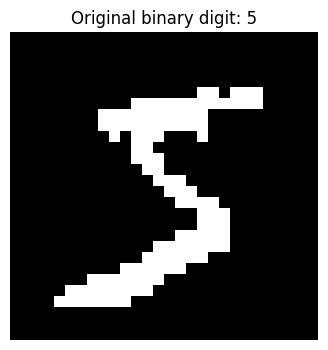

In [13]:
(X_train_raw, y_train), (X_test_raw, y_test) = mnist.load_data()

def binarize_image(image, threshold=THRESHOLD):
    """Return a uint8 binary image with foreground pixels equal to 255."""
    return ((image > threshold).astype(np.uint8) * 255)

binary_image = binarize_image(X_train_raw[IMAGE_INDEX])

print("Image shape:", binary_image.shape)
print("Digit label:", y_train[IMAGE_INDEX])

plt.figure(figsize=(4, 4))
plt.imshow(binary_image, cmap="gray")
plt.title(f"Original binary digit: {y_train[IMAGE_INDEX]}")
plt.axis("off")
plt.show()

## 3. Detect the external boundary

In [14]:
def extract_largest_external_contour(binary_image):
    """Find and return the largest external contour, or None if none exists."""
    if binary_image.ndim != 2:
        raise ValueError("Expected a 2D binary image.")

    image_uint8 = (binary_image > 0).astype(np.uint8) * 255
    contours, _ = cv2.findContours(
        image_uint8.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not contours:
        return None

    return max(contours, key=cv2.contourArea)

contour = extract_largest_external_contour(binary_image)

if contour is None:
    print("No external contour was found.")
else:
    print("Contour points:", len(contour))
    print("Contour area:", cv2.contourArea(contour))

Contour points: 79
Contour area: 70.5


## 4. Draw the detected boundary

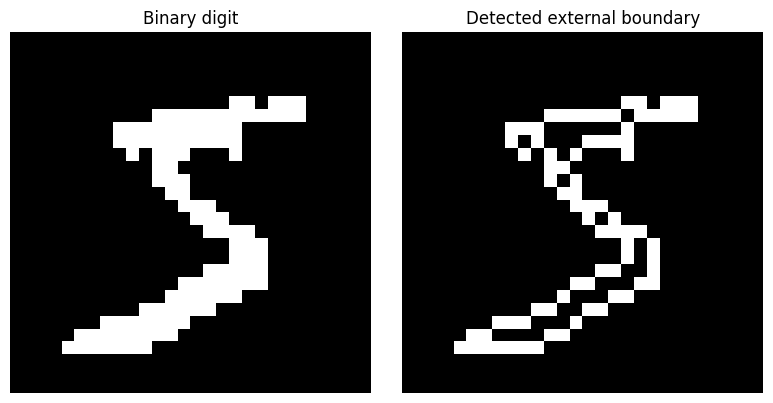

In [15]:
if contour is not None:
    boundary_image = np.zeros_like(binary_image)
    cv2.drawContours(boundary_image, [contour], contourIdx=-1, color=255, thickness=1)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(binary_image, cmap="gray")
    axes[0].set_title("Binary digit")
    axes[0].axis("off")

    axes[1].imshow(boundary_image, cmap="gray")
    axes[1].set_title("Detected external boundary")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

## 5. Define the 8-connected Freeman directions

OpenCV stores contour points as `(x, y)`. In the mapping below, the displacement is stored as `(dy, dx)`, where image rows increase downwards.

In [17]:
directions = {
    (0, 1): 0,    # E
    (-1, 1): 1,   # NE
    (-1, 0): 2,   # N
    (-1, -1): 3,  # NW
    (0, -1): 4,   # W
    (1, -1): 5,   # SW
    (1, 0): 6,    # S
    (1, 1): 7     # SE
}

direction_names = {
    0: "E", 1: "NE", 2: "N", 3: "NW",
    4: "W", 5: "SW", 6: "S", 7: "SE"
}

## 6. Convert the contour to Chain Code

In [18]:
def get_chain_code(contour):
    """Convert an OpenCV contour into an 8-direction Freeman chain code."""
    if contour is None or len(contour) == 0:
        return []

    points = contour.reshape(-1, 2)  # each point is (x, y)
    chain_code = []

    for index in range(len(points)):
        x1, y1 = points[index]
        x2, y2 = points[(index + 1) % len(points)]  # close the contour

        dx = int(np.sign(x2 - x1))
        dy = int(np.sign(y2 - y1))
        step = (dy, dx)

        if step == (0, 0):
            continue
        if step not in directions:
            raise ValueError(
                f"Non-8-connected contour step detected: {step}. "
                "Use CHAIN_APPROX_NONE when finding contours."
            )

        chain_code.append(directions[step])

    return chain_code

chain_code = get_chain_code(contour)

print("First 50 direction codes:", chain_code[:50])
print("Total chain-code length:", len(chain_code))
print("Direction names:", [direction_names[c] for c in chain_code[:20]])

First 50 direction codes: [5, 4, 4, 4, 4, 4, 5, 4, 4, 6, 7, 1, 7, 6, 6, 7, 7, 7, 7, 0, 7, 6, 5, 4, 5, 4, 5, 5, 4, 5, 4, 4, 5, 4, 5, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0]
Total chain-code length: 79
Direction names: ['SW', 'W', 'W', 'W', 'W', 'W', 'SW', 'W', 'W', 'S', 'SE', 'NE', 'SE', 'S', 'S', 'SE', 'SE', 'SE', 'SE', 'E']


## 7. Visualize sampled chain-code directions

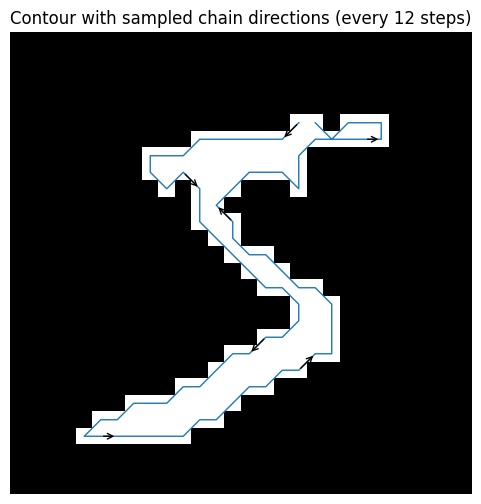

In [19]:
def visualize_chain_directions(image, contour, chain_code, step=12):
    """Overlay the contour and draw an arrow for every `step` contour points."""
    if contour is None or len(contour) == 0:
        print("No contour to visualize.")
        return
    if step < 1:
        raise ValueError("step must be a positive integer.")

    points = contour.reshape(-1, 2)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image, cmap="gray")

    contour_xy = points
    ax.plot(contour_xy[:, 0], contour_xy[:, 1], linewidth=1)

    for index in range(0, len(chain_code), step):
        x1, y1 = points[index]
        x2, y2 = points[(index + 1) % len(points)]
        ax.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops={"arrowstyle": "->", "lw": 1}
        )

    ax.set_title(f"Contour with sampled chain directions (every {step} steps)")
    ax.axis("off")
    plt.show()

visualize_chain_directions(binary_image, contour, chain_code, step=12)

## 8. Inspect the direction-code distribution

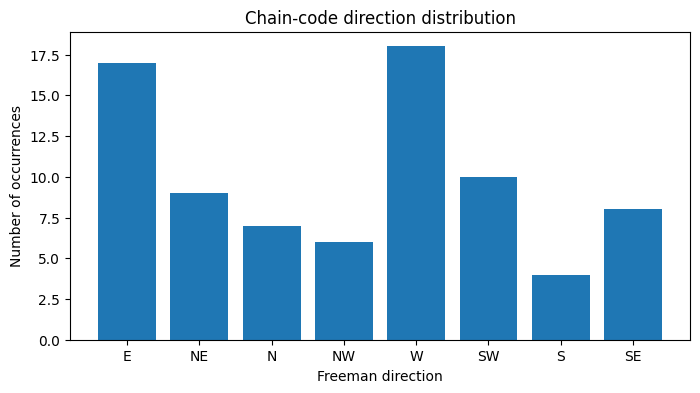

In [20]:
if chain_code:
    counts = np.bincount(chain_code, minlength=8)
    plt.figure(figsize=(8, 4))
    plt.bar([direction_names[i] for i in range(8)], counts)
    plt.xlabel("Freeman direction")
    plt.ylabel("Number of occurrences")
    plt.title("Chain-code direction distribution")
    plt.show()
else:
    print("The chain code is empty because no valid contour was extracted.")

## 9. Save the extracted chain code

In [21]:
if contour is not None:
    with open("mnist_chain_code.txt", "w", encoding="utf-8") as file:
        file.write(f"Image index: {IMAGE_INDEX}\\n")
        file.write(f"Digit label: {int(y_train[IMAGE_INDEX])}\\n")
        file.write(f"Chain code: {' '.join(map(str, chain_code))}\\n")
    print("Saved chain code to mnist_chain_code.txt")

Saved chain code to mnist_chain_code.txt


## Notes and limitations

- `cv2.RETR_EXTERNAL` extracts only outer contours; internal holes are not represented.
- The largest external contour is selected to avoid relying on the arbitrary order returned by OpenCV.
- `cv2.CHAIN_APPROX_NONE` retains contour points so consecutive points can be represented by 8-connected directions.
- The resulting chain code depends on the contour's starting point and traversal orientation. A normalized chain code can be added when comparing shapes independent of these choices.
- This is a boundary representation exercise, not a digit classification model.